# Diseño y Análisis de Experimentos
## Semana 5 · Capítulo 4 — Diseños en Bloques

**DBCA · Diseños con factor de bloque aleatorio · DCL · DCGL · BIBD**

Universidad Tecnológica de Bolívar — Estadística y Probabilidad

---

### Contenido de la semana

1. Teoría — Diseño en Bloques Completos al Azar (DBCA)
2. Ejemplo 1 — Comparación de métodos de ensamble (DBCA, efectos fijos)
3. Teoría — Diseños con factor de bloque aleatorio
4. Ejemplo 2 — Compuestos para reducir el consumo de gasolina (bloques aleatorios + dato perdido)
5. Diseño Cuadrado Latino (DCL) — teoría y ejercicio
6. Diseño Cuadrado Grecolatino (DCGL) — teoría y ejercicio
7. Diseños de Bloques Incompletos Balanceados (BIBD) — teoría y ejercicio
8. Resumen del capítulo

> **Fuente principal de los ejemplos 1 y 2:** Gutiérrez Pulido, H., & de la Vara Salazar, R. (2008). *Análisis y diseño de experimentos* (2.ª ed.). McGraw-Hill. Cap. 4, Diseños de bloques.


In [1]:
# =====================================================================
# Librerías de trabajo
# =====================================================================
import numpy as np
import pandas as pd
from scipy import stats

import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.libqsturng import qsturng, psturng

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titleweight"] = "bold"

pd.set_option("display.precision", 4)

print("Entorno listo.")


Entorno listo.


In [2]:
# =====================================================================
# Funciones de apoyo reutilizables para todo el capítulo
# =====================================================================

def anova_bloques(df, y, tratamiento, bloque, bloque_aleatorio=False, typ=2):
    """Ajusta el modelo Y ~ Tratamiento + Bloque (DBCA / bloque aleatorio)
    y devuelve la tabla ANOVA (statsmodels), el modelo ajustado y el CME.
    El tratamiento de "bloque aleatorio" no cambia las sumas de cuadrados
    (son las mismas que en el caso de efectos fijos); solo cambia la
    interpretación de la prueba F para el bloque, que en ese caso evalúa
    sigma^2_bloque = 0.
    """
    formula = f"{y} ~ C({tratamiento}) + C({bloque})"
    modelo = smf.ols(formula, data=df).fit()
    tabla = sm.stats.anova_lm(modelo, typ=typ)
    tabla = tabla.rename(index={f"C({tratamiento})": "Tratamiento",
                                 f"C({bloque})": "Bloque",
                                 "Residual": "Error"})
    cme = tabla.loc["Error", "sum_sq"] / tabla.loc["Error", "df"]
    return tabla, modelo, cme


def resumen_anova(tabla):
    """Imprime la tabla ANOVA con formato de Fuente / SC / gl / CM / F0 / valor-p."""
    t = tabla.copy()
    t["mean_sq"] = t["sum_sq"] / t["df"]
    t = t[["sum_sq", "df", "mean_sq", "F", "PR(>F)"]]
    t.columns = ["SC", "gl", "CM", "F0", "valor-p"]
    return t.round(4)


def tukey_hsd(medias, n, dfE, cme, alpha=0.05):
    """Prueba de Tukey (HSD) para comparaciones múltiples con igual número
    de observaciones por tratamiento (n). `medias` es un dict {trat: media}.
    Devuelve un DataFrame con todas las comparaciones por pares.
    """
    niveles = list(medias.keys())
    k = len(niveles)
    q_crit = qsturng(1 - alpha, k, dfE)
    hsd = q_crit * np.sqrt(cme / n)
    filas = []
    for i in range(k):
        for j in range(i + 1, k):
            a, b = niveles[i], niveles[j]
            diff = medias[a] - medias[b]
            q_obs = abs(diff) / np.sqrt(cme / n)
            p_val = psturng(q_obs, k, dfE)
            p_val = float(np.atleast_1d(p_val)[0])
            filas.append({
                "Comparación": f"{a} - {b}",
                "Diferencia": diff,
                "q": q_obs,
                "valor-p": p_val,
                "¿Signif.?": "Sí" if abs(diff) > hsd else "No",
            })
    resultado = pd.DataFrame(filas)
    return resultado, hsd, q_crit


def fisher_lsd(medias, n, dfE, cme, alpha=0.05):
    """Prueba LSD de Fisher para comparaciones múltiples (n observaciones
    por tratamiento). `medias` es un dict {trat: media}."""
    niveles = list(medias.keys())
    k = len(niveles)
    t_crit = stats.t.ppf(1 - alpha / 2, dfE)
    lsd = t_crit * np.sqrt(2 * cme / n)
    filas = []
    for i in range(k):
        for j in range(i + 1, k):
            a, b = niveles[i], niveles[j]
            diff = medias[a] - medias[b]
            se = np.sqrt(2 * cme / n)
            t_obs = diff / se
            p_val = 2 * (1 - stats.t.cdf(abs(t_obs), dfE))
            filas.append({
                "Comparación": f"{a} - {b}",
                "Diferencia": diff,
                "t0": t_obs,
                "valor-p": p_val,
                "¿Signif.?": "Sí" if abs(diff) > lsd else "No",
            })
    resultado = pd.DataFrame(filas)
    return resultado, lsd, t_crit


def graficar_medias_ic(df, y, factor, alpha=0.05, titulo="Gráfico de medias (IC 95%)"):
    """Grafica la media de cada nivel del factor con su intervalo de
    confianza individual (t de Student, usando la varianza de cada grupo)."""
    grupos = df.groupby(factor)[y]
    medias = grupos.mean()
    n = grupos.count()
    s = grupos.std()
    t_crit = stats.t.ppf(1 - alpha / 2, n - 1)
    err = t_crit * s / np.sqrt(n)

    fig, ax = plt.subplots()
    ax.errorbar(medias.index.astype(str), medias.values, yerr=err.values,
                fmt="o-", capsize=5, color="#2563eb", ecolor="#2563eb",
                markersize=8, linewidth=1.5)
    ax.set_xlabel(factor)
    ax.set_ylabel(y)
    ax.set_title(titulo)
    plt.tight_layout()
    return fig, ax


def graficar_residuos(modelo, df, factor, titulo_prefijo=""):
    """Cuatro gráficos de diagnóstico de residuos: vs. niveles del factor,
    vs. predichos, vs. orden de corrida y probabilidad normal."""
    residuos = modelo.resid
    predichos = modelo.fittedvalues

    fig, axes = plt.subplots(2, 2, figsize=(11, 8))

    axes[0, 0].scatter(df[factor].astype(str), residuos, color="#2563eb")
    axes[0, 0].axhline(0, color="red", linestyle="--")
    axes[0, 0].set_xlabel(factor)
    axes[0, 0].set_ylabel("Residuos")
    axes[0, 0].set_title("Residuos vs. Factor")

    axes[0, 1].scatter(predichos, residuos, color="#16a34a")
    axes[0, 1].axhline(0, color="red", linestyle="--")
    axes[0, 1].set_xlabel("Valores predichos")
    axes[0, 1].set_ylabel("Residuos")
    axes[0, 1].set_title("Residuos vs. Predichos")

    axes[1, 0].plot(range(1, len(residuos) + 1), residuos, "o-", color="#dc2626")
    axes[1, 0].axhline(0, color="red", linestyle="--")
    axes[1, 0].set_xlabel("Orden de corrida")
    axes[1, 0].set_ylabel("Residuos")
    axes[1, 0].set_title("Residuos vs. Orden de corrida")

    sm.qqplot(residuos, line="45", fit=True, ax=axes[1, 1], markerfacecolor="#7c3aed",
              markeredgecolor="#7c3aed")
    axes[1, 1].set_title("Gráfico de probabilidad normal")

    fig.suptitle(f"{titulo_prefijo}Diagnóstico de residuos", fontweight="bold")
    plt.tight_layout()
    return fig, axes

print("Funciones auxiliares definidas: anova_bloques, resumen_anova, tukey_hsd, "
      "fisher_lsd, graficar_medias_ic, graficar_residuos")


Funciones auxiliares definidas: anova_bloques, resumen_anova, tukey_hsd, fisher_lsd, graficar_medias_ic, graficar_residuos


## 1. Teoría — Diseño en Bloques Completos al Azar (DBCA)

### 1.1 Concepto de bloque

Un **bloque** es un conjunto de unidades experimentales homogéneas que se agrupan para
controlar la variabilidad debida a factores no controlables (ni de interés directo, pero que
afectan la respuesta). El bloqueo permite **reducir el error experimental** al remover la
variabilidad *entre* bloques de la variabilidad total, dejando que la comparación de
tratamientos se haga en condiciones más homogéneas *dentro* de cada bloque.

> *"El bloqueo elimina la variabilidad entre bloques y aumenta la precisión del experimento."*

### 1.2 Características del DBCA

1. Se tienen **bloques** que agrupan unidades experimentales homogéneas.
2. Cada bloque contiene **todos los tratamientos** (diseño *completo*).
3. La **aleatorización** se realiza *dentro* de cada bloque.
4. Se controla **una** fuente de variabilidad (el bloque).
5. El modelo incluye **el efecto del bloque** como factor adicional.

| | Bloque 1 | Bloque 2 | Bloque 3 |
|---|---|---|---|
| Aleatorización | T1,T2,T3,T4 (orden al azar) | T3,T1,T4,T2 (orden al azar) | T2,T4,T1,T3 (orden al azar) |

Cada bloque contiene **todos** los tratamientos, aleatorizados de forma independiente
dentro de cada bloque.


### 1.3 Modelo estadístico para el DBCA

$$Y_{ij} = \mu + \tau_i + \beta_j + \varepsilon_{ij}, \qquad i = 1,2,\dots,k; \quad j = 1,2,\dots,b$$

donde:

* $Y_{ij}$: observación del $i$-ésimo tratamiento en el $j$-ésimo bloque.
* $\mu$: media global común.
* $\tau_i$: efecto del $i$-ésimo tratamiento, con $\sum_i \tau_i = 0$.
* $\beta_j$: efecto del $j$-ésimo bloque, con $\sum_j \beta_j = 0$.
* $\varepsilon_{ij}$: error aleatorio, $\varepsilon_{ij} \sim N(0, \sigma^2)$ independientes.

**Supuestos:** normalidad e independencia de los errores, homogeneidad de varianza, y
**no interacción** entre tratamiento y bloque (efectos aditivos).

### 1.4 Hipótesis a probar

La hipótesis de interés es la misma para todos los diseños comparativos:

$$H_0: \mu_1 = \mu_2 = \cdots = \mu_k \qquad H_1: \mu_i \neq \mu_j \ \text{para algún } i \neq j$$

Puesto que $\mu_i = \mu + \tau_i$, las hipótesis son equivalentes a:

$$H_0: \tau_1 = \tau_2 = \cdots = \tau_k = 0 \qquad H_1: \tau_i \neq 0 \ \text{para algún } i$$

### 1.5 Notación sumatoria

$$Y_{i \cdot} = \sum_{j=1}^{b} Y_{ij} \quad\text{(total del tratamiento } i)$$
$$Y_{\cdot j} = \sum_{i=1}^{k} Y_{ij} \quad\text{(total del bloque } j)$$
$$Y_{\cdot \cdot} = \sum_{i=1}^{k}\sum_{j=1}^{b} Y_{ij} \quad\text{(total general)}$$

$$\bar{Y}_{i \cdot} = \frac{Y_{i \cdot}}{b}, \qquad \bar{Y}_{\cdot j} = \frac{Y_{\cdot j}}{k}, \qquad \bar{Y}_{\cdot \cdot} = \frac{Y_{\cdot \cdot}}{kb}$$


### 1.6 Análisis de varianza para el DBCA

**Sumas de cuadrados**

$$SCT = \sum_{i=1}^{k}\sum_{j=1}^{b} Y_{ij}^2 - \frac{Y_{\cdot\cdot}^2}{kb}$$
$$SCTr = \sum_{i=1}^{k} \frac{Y_{i\cdot}^2}{b} - \frac{Y_{\cdot\cdot}^2}{kb}$$
$$SCB = \sum_{j=1}^{b} \frac{Y_{\cdot j}^2}{k} - \frac{Y_{\cdot\cdot}^2}{kb}$$
$$SCE = SCT - SCTr - SCB$$

**Grados de libertad:** $SCTr \to k-1$, $\;SCB \to b-1$, $\;SCE \to (k-1)(b-1)$, $\;SCT \to kb-1$.

**Tabla ANOVA**

| Fuente | SC | gl | CM | $F_0$ |
|---|---|---|---|---|
| Tratamientos | $SCTr$ | $k-1$ | $CMTr = SCTr/(k-1)$ | $CMTr / CME$ |
| Bloques | $SCB$ | $b-1$ | $CMB = SCB/(b-1)$ | $CMB / CME$ |
| Error | $SCE$ | $(k-1)(b-1)$ | $CME = SCE/[(k-1)(b-1)]$ | — |
| Total | $SCT$ | $kb-1$ | — | — |

**Regla de decisión:** se rechaza $H_0$ si el valor-$p < \alpha$ (usualmente $\alpha = 0.05$).


## 2. Ejemplo 1 — Comparación de métodos de ensamble (DBCA)

### Planteamiento del problema

Un equipo de mejora investiga el efecto de **cuatro métodos de ensamble A, B, C y D** sobre
el **tiempo de ensamble** (en minutos). Los experimentadores consideran que los
**operadores** pueden afectar de manera significativa los tiempos de ensamble, por lo que
deciden usar el **diseño en bloques completos al azar (DBCA)**, bloqueando por operador.

* **Factor de interés (tratamiento):** método de ensamble — 4 niveles (A, B, C, D).
* **Bloque:** operador — 4 niveles (1, 2, 3, 4).
* **Variable respuesta:** tiempo de ensamble (minutos).
* $k = 4$ métodos, $b = 4$ operadores, $N = kb = 16$.

**Datos del experimento**

| Operador | A | B | C | D | $Y_{\cdot j}$ |
|---|---|---|---|---|---|
| 1 | 6 | 7 | 10 | 10 | 33 |
| 2 | 9 | 10 | 16 | 13 | 48 |
| 3 | 7 | 11 | 11 | 11 | 40 |
| 4 | 8 | 8 | 14 | 9 | 39 |
| $Y_{i\cdot}$ | 30 | 36 | 51 | 43 | $Y_{\cdot\cdot}=160$ |


In [3]:
# =====================================================================
# Ejemplo 1: datos del experimento en formato "largo" (tidy)
# =====================================================================
datos1 = pd.DataFrame({
    "operador": [1, 1, 1, 1,  2, 2, 2, 2,  3, 3, 3, 3,  4, 4, 4, 4],
    "metodo":   ["A", "B", "C", "D"] * 4,
    "tiempo":   [6, 7, 10, 10,
                 9, 10, 16, 13,
                 7, 11, 11, 11,
                 8, 8, 14, 9],
})

tabla_ancha1 = datos1.pivot(index="operador", columns="metodo", values="tiempo")
tabla_ancha1["Y_.j (total bloque)"] = tabla_ancha1.sum(axis=1)
tabla_ancha1.loc["Y_i. (total trat.)"] = tabla_ancha1.sum(axis=0)
tabla_ancha1


metodo,A,B,C,D,Y_.j (total bloque)
operador,,,,,
1,6,7,10,10,33
2,9,10,16,13,48
3,7,11,11,11,40
4,8,8,14,9,39
Y_i. (total trat.),30,36,51,43,160


In [4]:
# =====================================================================
# ANOVA para el DBCA (Ejemplo 1)
# =====================================================================
tabla1, modelo1, cme1 = anova_bloques(datos1, "tiempo", "metodo", "operador")
resumen_anova(tabla1)


,SC,gl,CM,F0,valor-p
Tratamiento,61.5,3.0,20.5,10.25,0.0029
Bloque,28.5,3.0,9.5,4.75,0.0298
Error,18.0,9.0,2.0,NaN,NaN


**Conclusión del ANOVA:** el valor-$p$ de *Métodos* es menor que $\alpha = 0.05$, por lo
que se **rechaza $H_0$**: existe evidencia estadísticamente significativa de que al menos un
par de métodos de ensamble presenta un tiempo medio diferente. El valor-$p$ de *Bloques*
también resulta significativo, lo que confirma que bloquear por operador fue una decisión
acertada (había variabilidad real entre operadores que el diseño logró controlar).


,Total,Promedio
metodo,,
A,30,7.50
B,36,9.00
C,51,12.75
D,43,10.75


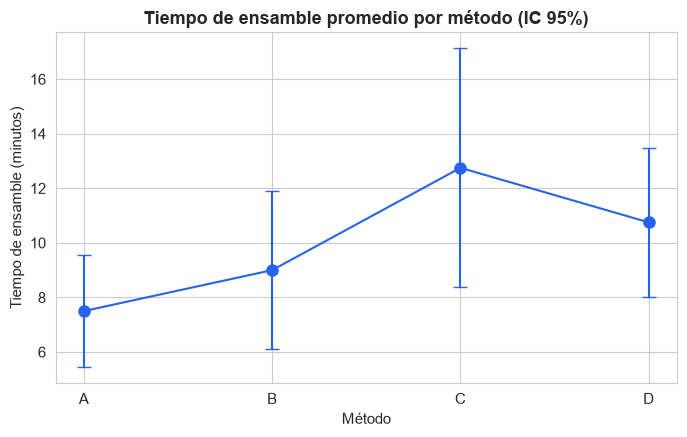

In [5]:
# =====================================================================
# Promedios por método + gráfico de medias con IC 95%
# =====================================================================
promedios1 = datos1.groupby("metodo")["tiempo"].agg(Total="sum", Promedio="mean")
display(promedios1)

graficar_medias_ic(datos1, "tiempo", "metodo",
                    titulo="Tiempo de ensamble promedio por método (IC 95%)")
plt.xlabel("Método")
plt.ylabel("Tiempo de ensamble (minutos)")
plt.show()


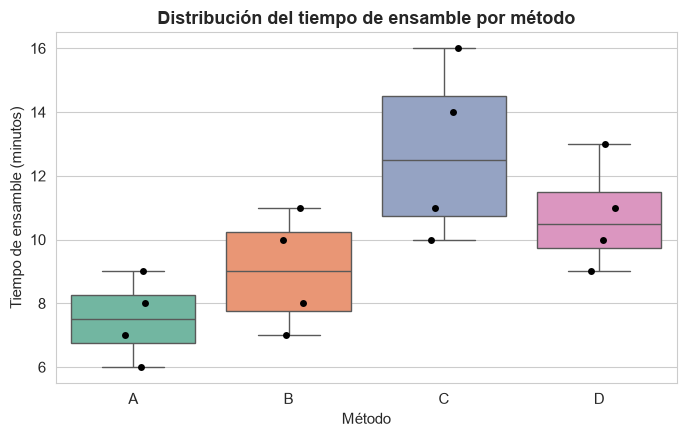

In [6]:
# =====================================================================
# Boxplot por método
# =====================================================================
fig, ax = plt.subplots()
sns.boxplot(data=datos1, x="metodo", y="tiempo", hue="metodo",
            order=["A", "B", "C", "D"], palette="Set2", legend=False, ax=ax)
sns.stripplot(data=datos1, x="metodo", y="tiempo", order=["A", "B", "C", "D"],
              color="black", size=5, ax=ax)
ax.set_xlabel("Método")
ax.set_ylabel("Tiempo de ensamble (minutos)")
ax.set_title("Distribución del tiempo de ensamble por método")
plt.tight_layout()
plt.show()


In [7]:
# =====================================================================
# Comparaciones múltiples: Tukey HSD y LSD de Fisher
# =====================================================================
medias1 = promedios1["Promedio"].to_dict()
b1 = datos1["operador"].nunique()          # observaciones por tratamiento
dfE1 = int(tabla1.loc["Error", "df"])

tukey1, hsd1, qcrit1 = tukey_hsd(medias1, n=b1, dfE=dfE1, cme=cme1)
print(f"CME = {cme1:.4f}   gl error = {dfE1}   q_crit(0.05) = {qcrit1:.4f}   HSD = {hsd1:.4f}\n")
display(tukey1.round(4))

lsd1, lsd_valor1, tcrit1 = fisher_lsd(medias1, n=b1, dfE=dfE1, cme=cme1)
print(f"\nt_crit(0.05) = {tcrit1:.4f}   LSD = {lsd_valor1:.4f}\n")
display(lsd1.round(4))


CME = 2.0000   gl error = 9   q_crit(0.05) = 4.4151   HSD = 3.1220



,Comparación,Diferencia,q,valor-p,¿Signif.?
0,A - B,-1.50,2.1213,0.4766,No
1,A - C,-5.25,7.4246,0.0024,Sí
2,A - D,-3.25,4.5962,0.0412,Sí
3,B - C,-3.75,5.3033,0.0196,Sí
4,B - D,-1.75,2.4749,0.3553,No
5,C - D,2.00,2.8284,0.2567,No



t_crit(0.05) = 2.2622   LSD = 2.2622



,Comparación,Diferencia,t0,valor-p,¿Signif.?
0,A - B,-1.50,-1.50,0.1679,No
1,A - C,-5.25,-5.25,0.0005,Sí
2,A - D,-3.25,-3.25,0.0100,Sí
3,B - C,-3.75,-3.75,0.0046,Sí
4,B - D,-1.75,-1.75,0.1140,No
5,C - D,2.00,2.00,0.0766,No


**Interpretación:**

* La prueba de **Tukey** (más conservadora, controla el error global de tipo I) señala cuáles
  diferencias por pares son significativas al 5 %.
* La prueba **LSD de Fisher** (más sensible, no ajusta por comparaciones múltiples) detecta
  con mayor facilidad diferencias entre pares, a costa de un mayor riesgo de error de tipo I.
* El método con **menor tiempo promedio** de ensamble es el preferible si el objetivo es
  minimizar el tiempo de producción.


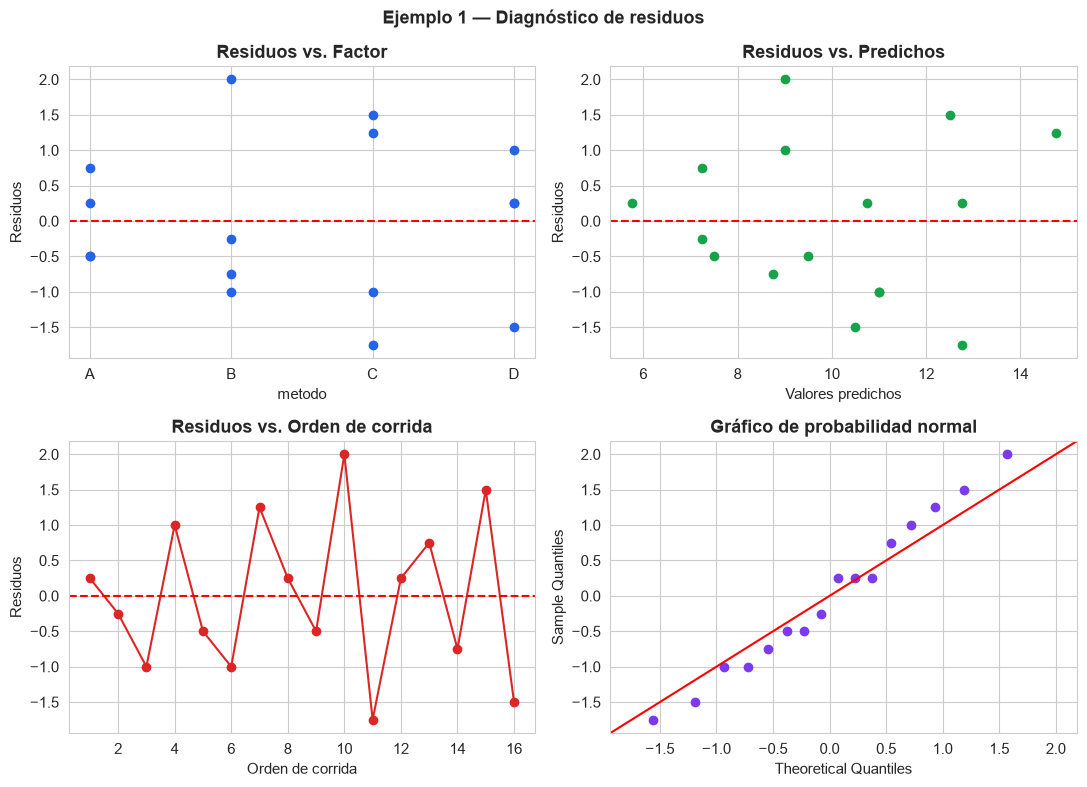

Shapiro-Wilk: W = 0.9730, valor-p = 0.8844
-> No se rechaza normalidad (p > 0.05)


In [8]:
# =====================================================================
# Diagnóstico de los supuestos del modelo (residuos)
# =====================================================================
graficar_residuos(modelo1, datos1, "metodo", titulo_prefijo="Ejemplo 1 — ")
plt.show()

# Prueba formal de normalidad de los residuos (Shapiro-Wilk)
shapiro1 = stats.shapiro(modelo1.resid)
print(f"Shapiro-Wilk: W = {shapiro1.statistic:.4f}, valor-p = {shapiro1.pvalue:.4f}")
print("-> " + ("No se rechaza normalidad (p > 0.05)" if shapiro1.pvalue > 0.05
               else "Se rechaza normalidad (p <= 0.05)"))


**Conclusión general del Ejemplo 1:** los residuos se distribuyen aleatoriamente
alrededor de cero, sin patrones evidentes frente a los niveles del factor, los valores
predichos o el orden de corrida, y el gráfico de probabilidad normal se ajusta razonablemente
a la recta. Esto es compatible con los supuestos del modelo DBCA (normalidad, varianza
constante e independencia), por lo que las conclusiones del ANOVA y de las pruebas de
comparación múltiple son confiables.


## 3. Diseños con factor de bloque aleatorio

### 3.1 Contexto

Hasta ahora tratamos el bloque como un factor de **efectos fijos**. Sin embargo, en muchas
situaciones experimentales los bloques representan una **muestra aleatoria** de una
población más amplia de condiciones (lotes, días, campos, vehículos, operadores, etc.). En
ese caso, el interés principal sigue estando en los **tratamientos** (efectos fijos), mientras
que los **bloques se consideran una fuente aleatoria de variación**.

> *"Tratar los bloques como aleatorios permite generalizar las conclusiones a una población
> más amplia de condiciones experimentales."*

### 3.2 Modelo estadístico

$$Y_{ij} = \mu + \tau_i + B_j + \varepsilon_{ij}, \qquad i = 1,\dots,k; \quad j = 1,\dots,b$$

donde:

* $\tau_i$: efecto (constante) del $i$-ésimo tratamiento, con $\sum \tau_i = 0$.
* $B_j$: efecto **aleatorio** del $j$-ésimo bloque, $B_j \sim N(0, \sigma_B^2)$ independientes.
* $\varepsilon_{ij} \sim N(0, \sigma^2)$ independientes.

### 3.3 Hipótesis

**Para los tratamientos (A):**
$$H_{0A}: \tau_1 = \tau_2 = \cdots = \tau_k = 0 \qquad H_{1A}: \text{algún } \tau_i \neq 0$$

**Para los bloques (B):**
$$H_{0B}: \sigma_B^2 = 0 \quad (\text{no hay variabilidad entre bloques}) \qquad H_{1B}: \sigma_B^2 > 0$$

### 3.4 Sumas de cuadrados, cuadrados medios esperados y tabla ANOVA

Las sumas de cuadrados y cuadrados medios se calculan **exactamente igual** que en el caso
de efectos fijos (la estructura de la tabla ANOVA de un DCA/DBCA no cambia). Lo que cambia
es la **interpretación**, reflejada en los cuadrados medios esperados:

$$E(CME) = \sigma^2 \qquad E(CMA) = \sigma^2 + \frac{b}{k-1}\sum_{i=1}^{k}\tau_i^2 \qquad E(CMB) = \sigma^2 + k\,\sigma_B^2$$

| Fuente | SC | gl | CM | $F_0$ | valor-$p$ |
|---|---|---|---|---|---|
| Tratamientos (A) | $SCTr$ | $k-1$ | $CMTr$ | $CMTr/CME$ | $P(F>F_0^A)$ |
| Bloques (B) | $SCB$ | $b-1$ | $CMB$ | $CMB/CME$ | $P(F>F_0^B)$ |
| Error | $SCE$ | $(k-1)(b-1)$ | $CME$ | — | — |
| Total | $SCT$ | $kb-1$ | — | — | — |

**Interpretación de resultados**

* Si se rechaza $H_{0A}$: existen diferencias significativas entre los tratamientos.
* Si se rechaza $H_{0B}$: hay evidencia de variabilidad entre bloques.
* Si no se rechaza $H_{0B}$: la variabilidad entre bloques no es significativa, pero **se
  mantiene en el modelo** porque así lo exigió el diseño experimental.

**Aplicaciones comunes:** ensayos agrícolas (lotes de terreno), procesos industriales (lotes
de producción), estudios en el tiempo (días/semanas), evaluación de operadores o equipos,
experimentos de laboratorio con condiciones variables.


## 4. Ejemplo 2 — Compuestos para reducir el consumo de gasolina (bloques aleatorios)

### Contexto del experimento

Para comprobar la utilidad de ciertos compuestos que, según sus fabricantes, reducen el
consumo de gasolina de los automóviles, una asociación de consumidores realizó el siguiente
experimento:

* Se eligieron al azar **9 vehículos nuevos** de distintas marcas con cilindrada similar.
* Con cada vehículo, un mismo conductor recorrió un mismo trayecto **tres veces**.
* En cada recorrido se utilizó un **compuesto diferente** para la gasolina.

| Compuesto | Descripción |
|---|---|
| A | Gasolina con Cyber-gas |
| B | Gasolina con Consumin |
| C | Gasolina sin aditivo |

* **Variable respuesta:** $Y_{ij}$ = consumo (en litros) de gasolina por el vehículo $j$ con
  el tratamiento de gasolina $i$ ($i=1,2,3$; $j=1,\dots,9$).
* **Factor (tratamiento):** compuesto de gasolina — 3 niveles.
* **Unidades experimentales:** los vehículos.
* **Bloques:** los 9 vehículos — **aleatorios**, ya que fueron seleccionados al azar.

**Modelo:** $Y_{ij} = \mu + \tau_i + \gamma_j + \varepsilon_{ij}$, con $\gamma_j \sim N(0,\sigma_\gamma^2)$.

**Hipótesis:**
$$H_{0A}: \tau_1=\tau_2=\tau_3=0 \quad\text{vs.}\quad H_{1A}: \text{algún } \tau_i \neq 0$$
$$H_{0B}: \sigma_\gamma^2 = 0 \quad\text{vs.}\quad H_{1B}: \sigma_\gamma^2 > 0$$

**Datos (consumo en litros).** Al revisar la información **no se pudo encontrar el dato**
correspondiente al compuesto **B** con el octavo vehículo (dato perdido).

| Vehículo | Recorrido 1 | Recorrido 2 | Recorrido 3 |
|---|---|---|---|
| 1 | 15.5 (A) | 15.6 (B) | 16.6 (C) |
| 2 | 13.0 (B) | 13.1 (A) | 13.5 (C) |
| 3 | 11.8 (B) | 13.4 (C) | 12.2 (A) |
| 4 | 14.2 (A) | 14.8 (C) | 15.0 (B) |
| 5 | 12.4 (B) | 14.0 (A) | 14.3 (C) |
| 6 | 15.6 (C) | 14.9 (A) | 14.7 (B) |
| 7 | 13.2 (C) | 12.0 (B) | 12.0 (A) |
| 8 | 14.9 (C) | **— (B)** | 15.0 (A) |
| 9 | 12.4 (A) | 13.5 (C) | 12.3 (B) |


In [9]:
# =====================================================================
# Ejemplo 2: datos en formato "largo", reordenados por Tratamiento x Vehículo
# El dato de (vehiculo=8, compuesto=B) se deja como NaN: es el dato perdido.
# =====================================================================
datos2 = pd.DataFrame({
    "vehiculo":  [1,1,1, 2,2,2, 3,3,3, 4,4,4, 5,5,5, 6,6,6, 7,7,7, 8,8,8, 9,9,9],
    "compuesto": ["A","B","C"] * 9,
    "consumo":   [15.5, 15.6, 16.6,
                  13.1, 13.0, 13.5,
                  12.2, 11.8, 13.4,
                  14.2, 15.0, 14.8,
                  14.0, 12.4, 14.3,
                  14.9, 14.7, 15.6,
                  12.0, 12.0, 13.2,
                  15.0, np.nan, 14.9,
                  12.4, 12.3, 13.5],
})

tabla_ancha2 = datos2.pivot(index="vehiculo", columns="compuesto", values="consumo")
tabla_ancha2


compuesto,A,B,C
vehiculo,,,
1,15.5,15.6,16.6
2,13.1,13.0,13.5
3,12.2,11.8,13.4
4,14.2,15.0,14.8
5,14.0,12.4,14.3
6,14.9,14.7,15.6
7,12.0,12.0,13.2
8,15.0,NaN,14.9
9,12.4,12.3,13.5


In [10]:
# =====================================================================
# Estimación del dato perdido (fórmula de Yates para DBCA)
#   y_hat = (k*T_i* + b*T_.j - T..) / [(k-1)(b-1)]
# donde T_i* es el total del tratamiento con el dato faltante (sin el dato),
# T_.j* es el total del bloque con el dato faltante (sin el dato), y T..* es
# el total general (sin el dato).
# =====================================================================
k2 = datos2["compuesto"].nunique()   # 3 tratamientos
b2 = datos2["vehiculo"].nunique()    # 9 bloques

Ti_B = datos2.loc[datos2["compuesto"] == "B", "consumo"].sum()          # total trat. B (sin el dato)
Tj_8 = datos2.loc[datos2["vehiculo"] == 8, "consumo"].sum()             # total vehículo 8 (sin el dato)
Tdd  = datos2["consumo"].sum()                                          # total general (sin el dato)

omega = (k2 * Ti_B + b2 * Tj_8 - Tdd) / ((k2 - 1) * (b2 - 1))
print(f"T_B* (sin el dato)      = {Ti_B}")
print(f"T_.8* (sin el dato)     = {Tj_8}")
print(f"T.. * (sin el dato)     = {Tdd}")
print(f"\nValor estimado para el dato perdido (vehículo 8, compuesto B):")
print(f"omega = ({k2}*{Ti_B} + {b2}*{Tj_8} - {Tdd}) / (({k2}-1)*({b2}-1)) = {omega:.4f}")

datos2.loc[(datos2["vehiculo"] == 8) & (datos2["compuesto"] == "B"), "consumo"] = omega
tabla_ancha2_completa = datos2.pivot(index="vehiculo", columns="compuesto", values="consumo")
tabla_ancha2_completa


T_B* (sin el dato)      = 106.8
T_.8* (sin el dato)     = 29.9
T.. * (sin el dato)     = 359.9

Valor estimado para el dato perdido (vehículo 8, compuesto B):
omega = (3*106.8 + 9*29.9 - 359.9) / ((3-1)*(9-1)) = 14.3500


compuesto,A,B,C
vehiculo,,,
1,15.5,15.60,16.6
2,13.1,13.00,13.5
3,12.2,11.80,13.4
4,14.2,15.00,14.8
5,14.0,12.40,14.3
6,14.9,14.70,15.6
7,12.0,12.00,13.2
8,15.0,14.35,14.9
9,12.4,12.30,13.5


> **Nota metodológica:** al estimar un dato perdido con la fórmula de Yates, el análisis de
> varianza resultante pierde **1 grado de libertad en el error** (porque ese valor no aporta
> información nueva, solo permite mantener el diseño balanceado). Es decir, $gl_{Error} =
> (k-1)(b-1) - 1$.


In [11]:
# =====================================================================
# ANOVA para el Ejemplo 2 (con el dato estimado)
# =====================================================================
tabla2, modelo2, cme2 = anova_bloques(datos2, "consumo", "compuesto", "vehiculo")

# Corrección de 1 gl en el error por el dato perdido estimado: al perder 1 gl
# el CME cambia, así que F0 y el valor-p de cada fuente deben recalcularse
# con el nuevo CME (no basta con editar el gl mostrado).
tabla2.loc["Error", "df"] -= 1
cme2 = tabla2.loc["Error", "sum_sq"] / tabla2.loc["Error", "df"]
dfE2_ajustado = tabla2.loc["Error", "df"]

for fuente in ["Tratamiento", "Bloque"]:
    cm_fuente = tabla2.loc[fuente, "sum_sq"] / tabla2.loc[fuente, "df"]
    F_fuente = cm_fuente / cme2
    tabla2.loc[fuente, "F"] = F_fuente
    tabla2.loc[fuente, "PR(>F)"] = 1 - stats.f.cdf(F_fuente, tabla2.loc[fuente, "df"], dfE2_ajustado)

resumen_anova(tabla2)


,SC,gl,CM,F0,valor-p
Tratamiento,4.5072,2.0,2.2536,12.3774,0.0007
Bloque,38.7733,8.0,4.8467,26.6192,0.0000
Error,2.7311,15.0,0.1821,NaN,NaN


**Conclusiones del ANOVA (Ejemplo 2):**

* El valor-$p$ de *Tratamiento (compuesto)* determina si existen diferencias significativas
  en el consumo medio de gasolina entre los tres compuestos.
* El valor-$p$ de *Bloque (vehículo)*, al tratarse de un bloque aleatorio, indica si existe
  evidencia de variabilidad real entre vehículos (se espera que sí, ya que se trata de
  marcas y cilindradas distintas).


,Total,Promedio
compuesto,,
A,123.30,13.7000
B,121.15,13.4611
C,129.80,14.4222


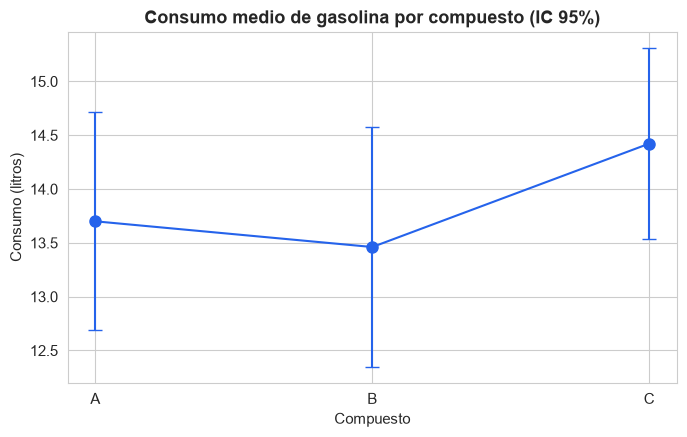

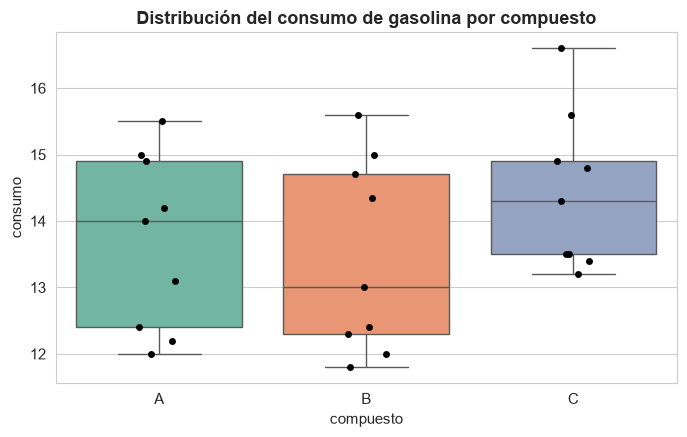

In [12]:
# =====================================================================
# Promedios por compuesto + gráfico de medias
# =====================================================================
promedios2 = datos2.groupby("compuesto")["consumo"].agg(Total="sum", Promedio="mean")
display(promedios2.round(4))

graficar_medias_ic(datos2, "consumo", "compuesto",
                    titulo="Consumo medio de gasolina por compuesto (IC 95%)")
plt.xlabel("Compuesto")
plt.ylabel("Consumo (litros)")
plt.show()

fig, ax = plt.subplots()
sns.boxplot(data=datos2, x="compuesto", y="consumo", hue="compuesto",
            order=["A", "B", "C"], palette="Set2", legend=False, ax=ax)
sns.stripplot(data=datos2, x="compuesto", y="consumo", order=["A", "B", "C"],
              color="black", size=5, ax=ax)
ax.set_title("Distribución del consumo de gasolina por compuesto")
plt.tight_layout()
plt.show()


In [13]:
# =====================================================================
# Comparaciones múltiples (Tukey y LSD) para el Ejemplo 2
# n por tratamiento = número de bloques (9), salvo que uno de los grupos
# tiene un valor estimado (no una observación real adicional); se usa n=b2
# como aproximación estándar del caso balanceado con dato perdido.
# =====================================================================
medias2 = promedios2["Promedio"].to_dict()
dfE2 = int(tabla2.loc["Error", "df"])

tukey2, hsd2, qcrit2 = tukey_hsd(medias2, n=b2, dfE=dfE2, cme=cme2)
print(f"CME = {cme2:.4f}   gl error = {dfE2}   HSD Tukey = {hsd2:.4f}\n")
display(tukey2.round(4))

lsd2, lsd_valor2, tcrit2 = fisher_lsd(medias2, n=b2, dfE=dfE2, cme=cme2)
print(f"\nLSD de Fisher = {lsd_valor2:.4f}\n")
display(lsd2.round(4))


CME = 0.1821   gl error = 15   HSD Tukey = 0.5223



,Comparación,Diferencia,q,valor-p,¿Signif.?
0,A - B,0.2389,1.6796,0.4795,No
1,A - C,-0.7222,5.0777,0.0071,Sí
2,B - C,-0.9611,6.7573,0.0010,Sí



LSD de Fisher = 0.4287



,Comparación,Diferencia,t0,valor-p,¿Signif.?
0,A - B,0.2389,1.1876,0.2534,No
1,A - C,-0.7222,-3.5905,0.0027,Sí
2,B - C,-0.9611,-4.7781,0.0002,Sí


**Conclusión práctica:** hay evidencia de que al menos un par de compuestos produce un
consumo medio de gasolina diferente. El compuesto con **menor consumo promedio** es el mejor
candidato como aditivo ahorrador; sin embargo, conviene revisar si esa diferencia es
significativa frente al testigo (gasolina sin aditivo, C) antes de recomendarlo comercialmente.


## 5. Diseño Cuadrado Latino (DCL)

### 5.1 Idea general

El DBCA controla **una** fuente de variabilidad extraña (el bloque). El **Diseño Cuadrado
Latino (DCL)** permite controlar **dos** fuentes de variabilidad extrañas de forma simultánea
(filas y columnas), usando un número de tratamientos $t$ igual al número de filas e igual al
número de columnas. Cada tratamiento aparece **exactamente una vez** en cada fila y en cada
columna — de ahí el nombre "cuadrado latino".

**Ejemplo de estructura para $t=4$** (letras = tratamiento; filas y columnas = los dos
factores de bloqueo):

| | Columna 1 | Columna 2 | Columna 3 | Columna 4 |
|---|---|---|---|---|
| **Fila 1** | A | B | C | D |
| **Fila 2** | B | C | D | A |
| **Fila 3** | C | D | A | B |
| **Fila 4** | D | A | B | C |

### 5.2 Modelo estadístico

$$Y_{ijl} = \mu + \alpha_i + \beta_j + \tau_l + \varepsilon_{ijl}$$

donde $i$ indexa la fila, $j$ la columna y $l$ el tratamiento (con la restricción de que solo
$t^2$ de las $t^3$ combinaciones posibles aparecen, una por cada tratamiento en cada fila y
columna). $\alpha_i$: efecto fila; $\beta_j$: efecto columna; $\tau_l$: efecto tratamiento;
todos suman cero. Se asume **no interacción** entre los tres factores.

### 5.3 Hipótesis de interés (usualmente solo sobre el tratamiento)

$$H_0: \tau_1 = \tau_2 = \cdots = \tau_t = 0 \qquad H_1: \text{algún } \tau_l \neq 0$$

### 5.4 Tabla ANOVA

| Fuente | SC | gl | CM | $F_0$ |
|---|---|---|---|---|
| Filas | $SC_{Fila}$ | $t-1$ | $SC_{Fila}/(t-1)$ | $CM_{Fila}/CME$ |
| Columnas | $SC_{Col}$ | $t-1$ | $SC_{Col}/(t-1)$ | $CM_{Col}/CME$ |
| Tratamientos | $SC_{Tr}$ | $t-1$ | $SC_{Tr}/(t-1)$ | $CM_{Tr}/CME$ |
| Error | $SCE$ | $(t-1)(t-2)$ | $CME$ | — |
| Total | $SCT$ | $t^2-1$ | — | — |

Cada suma de cuadrados se calcula igual que en el DBCA, pero ahora hay **tres** clasificaciones
cruzadas (fila, columna, tratamiento) en lugar de dos.


### 5.5 Ejercicio resuelto (ilustrativo)

Una fábrica quiere comparar **4 operarios (A, B, C, D)** en cuanto al **tiempo de ensamble**
(minutos) de un mismo producto. Para controlar dos posibles fuentes de variación —el **turno**
de trabajo (4 turnos) y la **máquina** utilizada (4 máquinas)— se organiza un diseño cuadrado
latino $4\times4$: cada operario trabaja exactamente una vez en cada turno y en cada máquina.

*(Datos ilustrativos construidos para fines pedagógicos.)*

| Turno \\ Máquina | M1 | M2 | M3 | M4 |
|---|---|---|---|---|
| T1 | 17 (A) | 19 (B) | 22 (C) | 25 (D) |
| T2 | 22 (B) | 21 (C) | 26 (D) | 18 (A) |
| T3 | 20 (C) | 21 (D) | 18 (A) | 20 (B) |
| T4 | 26 (D) | 16 (A) | 23 (B) | 26 (C) |


In [14]:
# =====================================================================
# Diseño Cuadrado Latino 4x4: operarios (tratamiento), turno (fila), máquina (columna)
# =====================================================================
cuadrado_latino = [
    ["A", "B", "C", "D"],
    ["B", "C", "D", "A"],
    ["C", "D", "A", "B"],
    ["D", "A", "B", "C"],
]
valores_dcl = [
    [17, 19, 22, 25],
    [22, 21, 26, 18],
    [20, 21, 18, 20],
    [26, 16, 23, 26],
]

filas_dcl = []
for i in range(4):
    for j in range(4):
        filas_dcl.append({
            "turno": f"T{i+1}",
            "maquina": f"M{j+1}",
            "operario": cuadrado_latino[i][j],
            "tiempo": valores_dcl[i][j],
        })
datos_dcl = pd.DataFrame(filas_dcl)

modelo_dcl = smf.ols("tiempo ~ C(turno) + C(maquina) + C(operario)", data=datos_dcl).fit()
tabla_dcl = sm.stats.anova_lm(modelo_dcl, typ=2)
tabla_dcl = tabla_dcl.rename(index={"C(turno)": "Filas (Turno)",
                                     "C(maquina)": "Columnas (Máquina)",
                                     "C(operario)": "Tratamiento (Operario)",
                                     "Residual": "Error"})
resumen_anova(tabla_dcl)


,SC,gl,CM,F0,valor-p
Filas (Turno),20.0,3.0,6.6667,6.1538,0.0291
Columnas (Máquina),24.0,3.0,8.0000,7.3846,0.0194
Tratamiento (Operario),110.5,3.0,36.8333,34.0000,0.0004
Error,6.5,6.0,1.0833,NaN,NaN


Promedios por operario: {'A': 17.25, 'B': 21.0, 'C': 22.25, 'D': 24.5}

CME = 1.0833   gl error = 6   HSD Tukey = 2.5481



,Comparación,Diferencia,q,valor-p,¿Signif.?
0,A - B,-3.75,7.2058,0.0089,Sí
1,A - C,-5.00,9.6077,0.0020,Sí
2,A - D,-7.25,13.9311,0.0010,Sí
3,B - C,-1.25,2.4019,0.4010,No
4,B - D,-3.50,6.7254,0.0124,Sí
5,C - D,-2.25,4.3235,0.0804,No


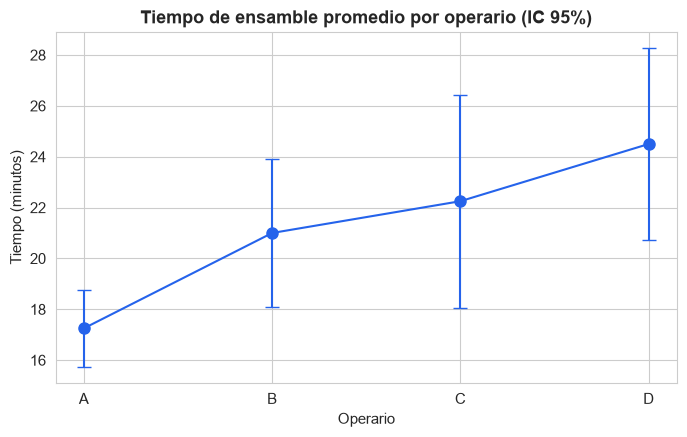

In [15]:
# =====================================================================
# Promedios por operario + comparación múltiple (Tukey)
# =====================================================================
promedios_dcl = datos_dcl.groupby("operario")["tiempo"].mean().to_dict()
print("Promedios por operario:", {k: round(v, 3) for k, v in promedios_dcl.items()})

cme_dcl = tabla_dcl.loc["Error", "sum_sq"] / tabla_dcl.loc["Error", "df"]
dfE_dcl = int(tabla_dcl.loc["Error", "df"])
t_dcl = len(promedios_dcl)  # cada operario tiene t=4 observaciones

tukey_dcl_res, hsd_dcl, _ = tukey_hsd(promedios_dcl, n=t_dcl, dfE=dfE_dcl, cme=cme_dcl)
print(f"\nCME = {cme_dcl:.4f}   gl error = {dfE_dcl}   HSD Tukey = {hsd_dcl:.4f}\n")
display(tukey_dcl_res.round(4))

graficar_medias_ic(datos_dcl, "tiempo", "operario",
                    titulo="Tiempo de ensamble promedio por operario (IC 95%)")
plt.xlabel("Operario")
plt.ylabel("Tiempo (minutos)")
plt.show()


**Conclusión:** al controlar simultáneamente el turno y la máquina mediante el diseño
cuadrado latino, el ANOVA aísla el efecto atribuible únicamente al operario. Si el valor-$p$
de *Tratamiento (Operario)* es menor que $\alpha$, se concluye que existen diferencias reales
en el tiempo de ensamble entre operarios, y la prueba de Tukey identifica cuáles pares
difieren de forma significativa.


## 6. Diseño Cuadrado Grecolatino (DCGL)

### 6.1 Idea general

El **Diseño Cuadrado Grecolatino** extiende el cuadrado latino para controlar **tres** fuentes
de variabilidad extrañas (filas, columnas y un tercer factor de bloqueo) **más** un segundo
factor de tratamiento, usando dos cuadrados latinos ortogonales superpuestos: uno con letras
latinas (A, B, C, D — primer tratamiento) y otro con letras griegas ($\alpha,\beta,\gamma,\delta$
— segundo tratamiento o tercer bloqueo). Dos cuadrados latinos son **ortogonales** cuando,
al superponerlos, cada combinación (letra latina, letra griega) aparece **exactamente una vez**.

**Estructura $4\times4$:**

| | Col 1 | Col 2 | Col 3 | Col 4 |
|---|---|---|---|---|
| **Fila 1** | A$\alpha$ | B$\beta$ | C$\gamma$ | D$\delta$ |
| **Fila 2** | B$\delta$ | A$\gamma$ | D$\beta$ | C$\alpha$ |
| **Fila 3** | C$\beta$ | D$\alpha$ | A$\delta$ | B$\gamma$ |
| **Fila 4** | D$\gamma$ | C$\delta$ | B$\alpha$ | A$\beta$ |

### 6.2 Modelo estadístico

$$Y_{ijlm} = \mu + \alpha_i + \beta_j + \tau_l + \omega_m + \varepsilon_{ijlm}$$

con $\alpha_i$ (fila), $\beta_j$ (columna), $\tau_l$ (tratamiento — letra latina), $\omega_m$
(tratamiento/bloque — letra griega), todos de suma cero, y sin interacciones entre ellos.

### 6.3 Tabla ANOVA ($t\times t$ cuadrado)

| Fuente | gl |
|---|---|
| Filas | $t-1$ |
| Columnas | $t-1$ |
| Tratamiento (Latino) | $t-1$ |
| Tratamiento/Bloque (Griego) | $t-1$ |
| Error | $(t-1)(t-3)$ |
| Total | $t^2-1$ |

Cada suma de cuadrados se calcula con la misma lógica que antes: SC de un factor = suma de
$(\text{total del nivel})^2/t$ menos el término de corrección, y $SCE$ se obtiene por
diferencia. El diseño requiere $t \geq 3$ (para $t=3$ el error queda con 0 gl, por lo que en
la práctica se usa desde $t \geq 4$).


### 6.4 Ejercicio resuelto (ilustrativo)

Se estudia el **rendimiento de combustible** (km/L) de un motor bajo 4 **formulaciones de
combustible** (tratamiento latino: A, B, C, D) y 4 **lotes de material aditivo** (tratamiento
griego: $\alpha,\beta,\gamma,\delta$), controlando por **operador** (fila) y **banco de
pruebas** (columna) mediante un cuadrado grecolatino $4\times4$.

*(Datos ilustrativos construidos para fines pedagógicos.)*


In [16]:
# =====================================================================
# Diseño Cuadrado Grecolatino 4x4
# =====================================================================
latino = [
    ["A", "B", "C", "D"],
    ["B", "A", "D", "C"],
    ["C", "D", "A", "B"],
    ["D", "C", "B", "A"],
]
griego = [
    ["a", "b", "g", "d"],   # alpha, beta, gamma, delta
    ["d", "g", "b", "a"],
    ["b", "a", "d", "g"],
    ["g", "d", "a", "b"],
]
valores_dcgl = [
    [16, 19, 23, 27],
    [24, 17, 26, 22],
    [20, 20, 20, 21],
    [27, 23, 22, 21],
]

filas_dcgl = []
for i in range(4):
    for j in range(4):
        filas_dcgl.append({
            "operador": f"F{i+1}",
            "banco": f"C{j+1}",
            "formulacion": latino[i][j],
            "lote": griego[i][j],
            "rendimiento": valores_dcgl[i][j],
        })
datos_dcgl = pd.DataFrame(filas_dcgl)

modelo_dcgl = smf.ols(
    "rendimiento ~ C(operador) + C(banco) + C(formulacion) + C(lote)",
    data=datos_dcgl
).fit()
tabla_dcgl = sm.stats.anova_lm(modelo_dcgl, typ=2)
tabla_dcgl = tabla_dcgl.rename(index={"C(operador)": "Filas (Operador)",
                                       "C(banco)": "Columnas (Banco)",
                                       "C(formulacion)": "Tratamiento (Formulación)",
                                       "C(lote)": "Bloque 2 (Lote, griego)",
                                       "Residual": "Error"})
resumen_anova(tabla_dcgl)


,SC,gl,CM,F0,valor-p
Filas (Operador),20.0,3.0,6.6667,20.0,0.0174
Columnas (Banco),24.0,3.0,8.0000,24.0,0.0134
Tratamiento (Formulación),85.0,3.0,28.3333,85.0,0.0021
"Bloque 2 (Lote, griego)",25.0,3.0,8.3333,25.0,0.0127
Error,1.0,3.0,0.3333,NaN,NaN


Promedios por formulación (latina):


formulacion
A    18.5
B    21.5
C    22.0
D    25.0
Name: rendimiento, dtype: float64


Promedios por lote de material (griega):


lote
a    20.0
b    21.5
d    23.5
g    22.0
Name: rendimiento, dtype: float64

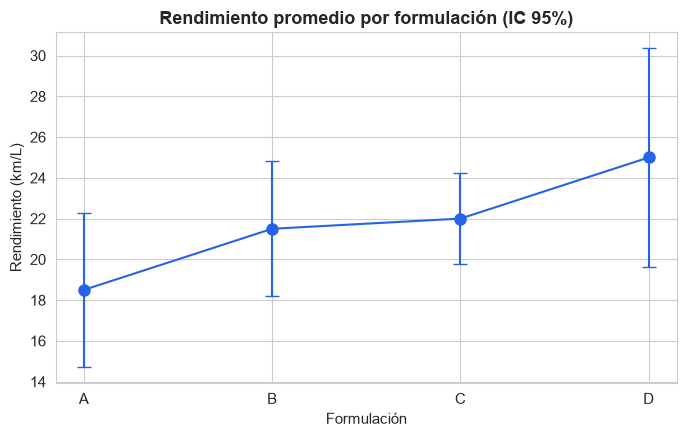

In [17]:
# =====================================================================
# Promedios por formulación y por lote
# =====================================================================
print("Promedios por formulación (latina):")
display(datos_dcgl.groupby("formulacion")["rendimiento"].mean().round(3))

print("\nPromedios por lote de material (griega):")
display(datos_dcgl.groupby("lote")["rendimiento"].mean().round(3))

graficar_medias_ic(datos_dcgl, "rendimiento", "formulacion",
                    titulo="Rendimiento promedio por formulación (IC 95%)")
plt.xlabel("Formulación")
plt.ylabel("Rendimiento (km/L)")
plt.show()


**Conclusión:** el DCGL permite evaluar **simultáneamente** el efecto de la formulación
de combustible y del lote de aditivo, mientras se controla el efecto de operador y banco de
pruebas — todo con un solo experimento de $t^2=16$ corridas en lugar de un diseño factorial
completo mucho más grande. Se interpretan los valores-$p$ de *Tratamiento (Formulación)* y
*Bloque 2 (Lote, griego)* de la misma manera que en el DCL.


### 6.5 Ejemplo aplicado — Lisina y proteína en la producción de leche (DCGL $7\times7$)

**Contexto.** Un equipo de investigación desea determinar el efecto del **porcentaje de lisina**
y del **porcentaje de proteína** de la dieta sobre la **producción de leche** en vacas.
Experimentos previos sugieren que la **interacción lisina $\times$ proteína es despreciable**, por lo
que puede usarse un diseño en cuadro grecolatino, que evalúa los dos factores de tratamiento
**simultáneamente** mientras controla tres fuentes de variabilidad extraña.

| Elemento del diseño | En este experimento |
|---|---|
| Tratamiento 1 (letras latinas) | **Lisina**: A, B, C, D, E, F, G = 0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6 % |
| Tratamiento 2 (letras griegas) | **Proteína**: $\alpha,\beta,\chi,\delta,\varepsilon,\phi,\gamma$ = 2, 4, 6, 8, 10, 12, 14 % |
| Bloque 1 (filas) | **Vacas** (7 animales elegidos al azar) |
| Bloque 2 (columnas) | **Periodos** (7 periodos de tres meses) |
| Unidades / corridas | $t^2 = 49$ observaciones |

**Modelo estadístico**

$$Y_{ijlm} = \mu + \tau_i + \rho_j + \kappa_l + \gamma_m + \varepsilon_{ijlm},
\qquad \varepsilon_{ijlm}\sim N(0,\sigma^2)$$

donde $\tau_i$ es el efecto del nivel $i$ de lisina, $\rho_j$ el del nivel $j$ de proteína,
$\kappa_l$ el de la vaca $l$, $\gamma_m$ el del periodo $m$.

**Grados de libertad:** cada fuente aporta $t-1 = 6$ y el error queda con
$(t-1)(t-3) = 6\times4 = 24$ gl, de un total de $t^2-1 = 48$.

In [18]:
# =====================================================================
# Datos del experimento: cuadro grecolatino 7x7 (vacas x periodos)
# Cada celda trae la produccion de leche y el par (letra latina, letra griega)
# =====================================================================
celdas_leche = [
    [(304, "A", "a"), (436, "B", "e"), (350, "C", "b"), (504, "D", "f"), (417, "E", "c"), (519, "F", "g"), (432, "G", "d")],
    [(381, "B", "b"), (505, "C", "f"), (425, "D", "c"), (564, "E", "g"), (494, "F", "d"), (350, "G", "a"), (413, "A", "e")],
    [(432, "C", "c"), (566, "D", "g"), (479, "E", "d"), (357, "F", "a"), (461, "G", "e"), (340, "A", "b"), (502, "B", "f")],
    [(442, "D", "d"), (372, "E", "a"), (536, "F", "e"), (366, "G", "b"), (495, "A", "f"), (425, "B", "c"), (507, "C", "g")],
    [(496, "E", "e"), (449, "F", "b"), (493, "G", "f"), (345, "A", "c"), (509, "B", "g"), (481, "C", "d"), (380, "D", "a")],
    [(534, "F", "f"), (421, "G", "c"), (452, "A", "g"), (427, "B", "d"), (346, "C", "a"), (478, "D", "e"), (397, "E", "b")],
    [(543, "G", "g"), (386, "A", "d"), (435, "B", "a"), (485, "C", "e"), (406, "D", "b"), (554, "E", "f"), (410, "F", "c")],
]

# Equivalencia letra griega (simbolo del enunciado) -> nivel de proteina
griega_simbolo = {"a": "alfa", "b": "beta", "c": "chi", "d": "delta",
                  "e": "epsilon", "f": "phi", "g": "gamma"}
pct_lisina   = dict(zip("ABCDEFG", [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6]))
pct_proteina = dict(zip("abcdefg", [2, 4, 6, 8, 10, 12, 14]))

filas = []
for i, fila in enumerate(celdas_leche):
    for j, (y, lat, gri) in enumerate(fila):
        filas.append({
            "vaca": f"V{i+1}",
            "periodo": f"P{j+1}",
            "lisina": lat,
            "proteina": gri,
            "lisina_pct": pct_lisina[lat],
            "proteina_pct": pct_proteina[gri],
            "leche": y,
        })
datos_leche = pd.DataFrame(filas)

# ---- Verificacion de que el arreglo SI es un cuadro grecolatino ------
ok_pares = datos_leche.groupby(["lisina", "proteina"]).size().eq(1).all()
ok_lat = (datos_leche.groupby(["vaca", "lisina"]).size().eq(1).all()
          and datos_leche.groupby(["periodo", "lisina"]).size().eq(1).all())
ok_gri = (datos_leche.groupby(["vaca", "proteina"]).size().eq(1).all()
          and datos_leche.groupby(["periodo", "proteina"]).size().eq(1).all())
print(f"Observaciones: {len(datos_leche)}   Media global: {datos_leche['leche'].mean():.2f} kg")
print(f"Cada combinacion latina-griega aparece exactamente una vez: {ok_pares}")
print(f"Cada letra latina una vez por vaca y por periodo:           {ok_lat}")
print(f"Cada letra griega una vez por vaca y por periodo:           {ok_gri}")
print("-> el arreglo es un cuadro grecolatino valido (dos cuadros latinos ortogonales)")

display(datos_leche.pivot(index="vaca", columns="periodo", values="leche"))


Observaciones: 49   Media global: 444.92 kg
Cada combinacion latina-griega aparece exactamente una vez: True
Cada letra latina una vez por vaca y por periodo:           True
Cada letra griega una vez por vaca y por periodo:           True
-> el arreglo es un cuadro grecolatino valido (dos cuadros latinos ortogonales)


periodo,P1,P2,P3,P4,P5,P6,P7
vaca,,,,,,,
V1,304,436,350,504,417,519,432
V2,381,505,425,564,494,350,413
V3,432,566,479,357,461,340,502
V4,442,372,536,366,495,425,507
V5,496,449,493,345,509,481,380
V6,534,421,452,427,346,478,397
V7,543,386,435,485,406,554,410


In [19]:
# =====================================================================
# ANOVA del diseño en cuadro grecolatino
#   Lisina (latino) + Proteina (griego) + Vacas (fila) + Periodos (columna)
# =====================================================================
modelo_leche = smf.ols(
    "leche ~ C(lisina) + C(proteina) + C(vaca) + C(periodo)",
    data=datos_leche
).fit()

tabla_leche = sm.stats.anova_lm(modelo_leche, typ=2)
tabla_leche = tabla_leche.rename(index={
    "C(lisina)": "Lisina (A, latino)",
    "C(proteina)": "Proteína (B, griego)",
    "C(vaca)": "Vacas (bloque 1)",
    "C(periodo)": "Periodos (bloque 2)",
    "Residual": "Error",
})

cme_leche = tabla_leche.loc["Error", "sum_sq"] / tabla_leche.loc["Error", "df"]
gl_error = int(tabla_leche.loc["Error", "df"])

anova_leche = resumen_anova(tabla_leche)
anova_leche.loc["Total"] = [tabla_leche["sum_sq"].sum(), tabla_leche["df"].sum(),
                            np.nan, np.nan, np.nan]
display(anova_leche)

print(f"CME = {cme_leche:.2f}   gl del error = {gl_error}   "
      f"F crítica(6, {gl_error}) al 5% = {stats.f.ppf(0.95, 6, gl_error):.3f}")
print(f"Desviación estándar del error: sqrt(CME) = {np.sqrt(cme_leche):.2f} kg")


,SC,gl,CM,F0,valor-p
"Lisina (A, latino)",30718.2449,6.0,5119.7075,7.9046,0.0001
"Proteína (B, griego)",160242.8163,6.0,26707.1361,41.2348,0.0000
Vacas (bloque 1),5831.9592,6.0,971.9932,1.5007,0.2204
Periodos (bloque 2),2124.2449,6.0,354.0408,0.5466,0.7676
Error,15544.4082,24.0,647.6837,NaN,NaN
Total,214461.6735,48.0,NaN,NaN,NaN


CME = 647.68   gl del error = 24   F crítica(6, 24) al 5% = 2.508
Desviación estándar del error: sqrt(CME) = 25.45 kg


**Conclusión del ANOVA.**

- **Lisina** ($F_0 = 7.90$, valor-$p < 0.001$) y **proteína** ($F_0 = 41.23$, valor-$p < 0.001$)
  tienen un efecto **altamente significativo** sobre la producción de leche. El efecto de la
  proteína es mucho mayor: su suma de cuadrados es más de **cinco veces** la de la lisina.
- **Vacas** (valor-$p = 0.22$) y **periodos** (valor-$p = 0.77$) **no** resultan significativos:
  en este experimento el bloqueo no era estrictamente necesario, pero *bloquear de más* solo
  cuesta grados de libertad, mientras que *no bloquear* habría escondido los efectos reales
  dentro del error.
- El diseño resume en **49 corridas** lo que un factorial completo $7\times7$ con réplicas
  requeriría en cientos de observaciones.

> **Nota sobre las cifras del enunciado.** La tabla ANOVA que aparece en el material del
> problema (SCT = 124 189.5) **no corresponde a la cuadrícula de datos publicada**: la suma de
> cuadrados total de esos 49 valores es $SCT = 214\,461.7$, y la $SCT$ no depende del arreglo
> del cuadro, solo de los datos. Las conclusiones cualitativas coinciden (lisina y proteína
> significativas, periodos no), pero los números de esta sección son los que realmente se
> obtienen de la tabla de datos del enunciado.

,Lisina (%),Media lisina,Proteína (%),Media proteína
A / a,0.0,390.71,2,363.43
B / b,0.1,445.00,4,384.14
C / c,0.2,443.71,6,410.71
D / d,0.3,457.29,8,448.71
E / e,0.4,468.43,10,472.14
F / f,0.5,471.29,12,512.43
G / g,0.6,438.00,14,522.86


Semiancho del IC 95% de cada media: +/- 19.85 kg


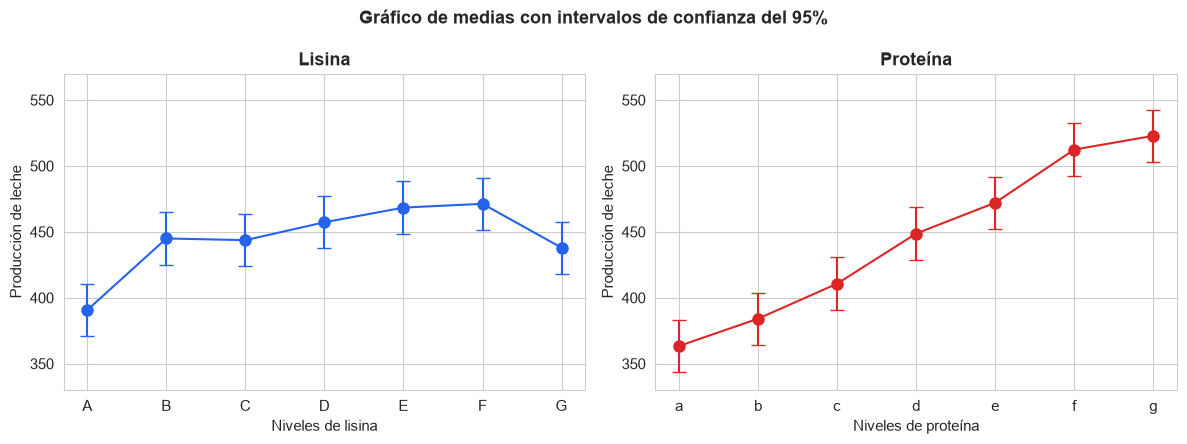

In [20]:
# =====================================================================
# Medias por nivel de cada factor + grafico de medias con IC 95%
# En un DCGL el intervalo se construye con el CME del modelo completo:
#        media_i  +/-  t(alpha/2, gl_error) * sqrt(CME / t)
# =====================================================================
t_cuadro = 7
t_crit_leche = stats.t.ppf(0.975, gl_error)
semi_ancho = t_crit_leche * np.sqrt(cme_leche / t_cuadro)

medias_lisina = datos_leche.groupby("lisina")["leche"].mean()
medias_proteina = datos_leche.groupby("proteina")["leche"].mean()

resumen_niveles = pd.DataFrame({
    "Lisina (%)": [pct_lisina[k] for k in medias_lisina.index],
    "Media lisina": medias_lisina.values,
    "Proteína (%)": [pct_proteina[k] for k in medias_proteina.index],
    "Media proteína": medias_proteina.values,
}, index=[f"{a} / {b}" for a, b in zip(medias_lisina.index, medias_proteina.index)])
display(resumen_niveles.round(2))
print(f"Semiancho del IC 95% de cada media: +/- {semi_ancho:.2f} kg")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, medias, nombre, color in [
    (axes[0], medias_lisina, "Lisina", "#2563eb"),
    (axes[1], medias_proteina, "Proteína", "#dc2626"),
]:
    ax.errorbar(medias.index.astype(str), medias.values, yerr=semi_ancho,
                fmt="o-", capsize=5, color=color, ecolor=color, markersize=8, linewidth=1.5)
    ax.set_title(nombre)
    ax.set_xlabel(f"Niveles de {nombre.lower()}")
    ax.set_ylabel("Producción de leche")
    ax.set_ylim(330, 570)
fig.suptitle("Gráfico de medias con intervalos de confianza del 95%", fontweight="bold")
plt.tight_layout()
plt.show()


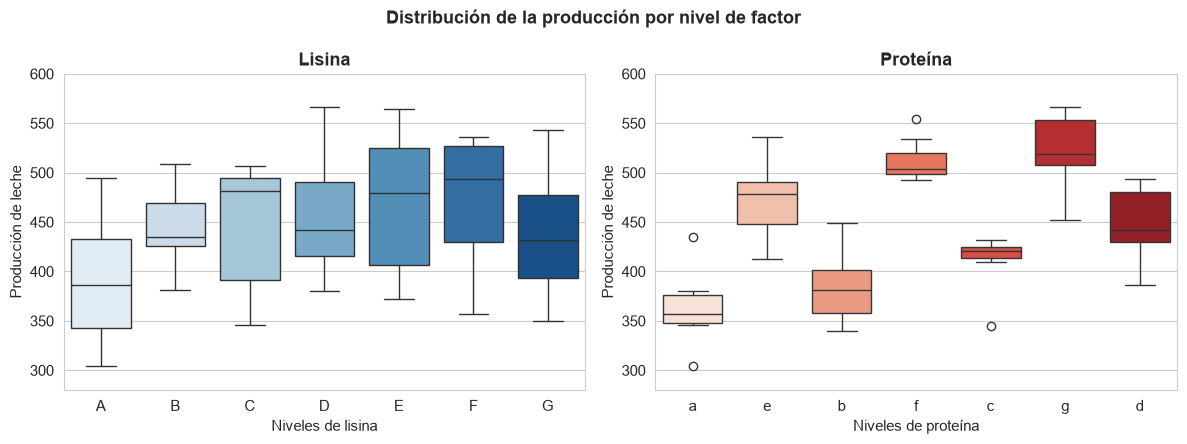

In [21]:
# =====================================================================
# Boxplots por nivel de cada factor
# =====================================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=datos_leche, x="lisina", y="leche", ax=axes[0], palette="Blues")
axes[0].set_title("Lisina")
axes[0].set_xlabel("Niveles de lisina")

sns.boxplot(data=datos_leche, x="proteina", y="leche", ax=axes[1], palette="Reds")
axes[1].set_title("Proteína")
axes[1].set_xlabel("Niveles de proteína")

for ax in axes:
    ax.set_ylabel("Producción de leche")
    ax.set_ylim(280, 600)
fig.suptitle("Distribución de la producción por nivel de factor", fontweight="bold")
plt.tight_layout()
plt.show()


In [22]:
# =====================================================================
# Comparaciones multiples: prueba HSD de Tukey (alpha = 0.05)
#   n = t = 7 observaciones por nivel;  gl del error = 24;  CME del DCGL
# =====================================================================
tukey_lis, hsd_lis, q_lis = tukey_hsd(medias_lisina.to_dict(), t_cuadro, gl_error, cme_leche)
tukey_pro, hsd_pro, q_pro = tukey_hsd(medias_proteina.to_dict(), t_cuadro, gl_error, cme_leche)

print(f"q(0.05; 7, {gl_error}) = {q_lis:.3f}      HSD = q*sqrt(CME/t) = "
      f"{q_lis:.3f}*sqrt({cme_leche:.1f}/7) = {hsd_lis:.2f} kg")
print("Dos medias difieren significativamente si |diferencia| > HSD.\n")

print(f"LISINA — comparaciones significativas ({(tukey_lis['¿Signif.?'] == 'Sí').sum()} de "
      f"{len(tukey_lis)}):")
display(tukey_lis[tukey_lis["¿Signif.?"] == "Sí"].round(4).reset_index(drop=True))

print(f"PROTEÍNA — comparaciones significativas ({(tukey_pro['¿Signif.?'] == 'Sí').sum()} de "
      f"{len(tukey_pro)}):")
display(tukey_pro[tukey_pro["¿Signif.?"] == "Sí"].round(4).reset_index(drop=True))


q(0.05; 7, 24) = 4.541      HSD = q*sqrt(CME/t) = 4.541*sqrt(647.7/7) = 43.68 kg
Dos medias difieren significativamente si |diferencia| > HSD.

LISINA — comparaciones significativas (6 de 21):


,Comparación,Diferencia,q,valor-p,¿Signif.?
0,A - B,-54.2857,5.6436,0.0084,Sí
1,A - C,-53.0000,5.5099,0.0106,Sí
2,A - D,-66.5714,6.9208,0.0010,Sí
3,A - E,-77.7143,8.0792,0.0010,Sí
4,A - F,-80.5714,8.3762,0.0010,Sí
5,A - G,-47.2857,4.9158,0.0279,Sí


PROTEÍNA — comparaciones significativas (15 de 21):


,Comparación,Diferencia,q,valor-p,¿Signif.?
0,a - c,-47.2857,4.9158,0.0279,Sí
1,a - d,-85.2857,8.8663,0.0010,Sí
2,a - e,-108.7143,11.3020,0.0010,Sí
3,a - f,-149.0000,15.4901,0.0010,Sí
4,a - g,-159.4286,16.5742,0.0010,Sí
5,b - d,-64.5714,6.7129,0.0013,Sí
6,b - e,-88.0000,9.1485,0.0010,Sí
7,b - f,-128.2857,13.3366,0.0010,Sí
8,b - g,-138.7143,14.4208,0.0010,Sí
9,c - e,-61.4286,6.3861,0.0024,Sí


In [23]:
# =====================================================================
# Comparaciones multiples: prueba LSD de Fisher (alpha = 0.05)
# =====================================================================
lsd_lis, valor_lsd, t_lsd = fisher_lsd(medias_lisina.to_dict(), t_cuadro, gl_error, cme_leche)
lsd_pro, _, _ = fisher_lsd(medias_proteina.to_dict(), t_cuadro, gl_error, cme_leche)

print(f"t(0.025, {gl_error}) = {t_lsd:.3f}      LSD = t*sqrt(2*CME/t) = "
      f"{t_lsd:.3f}*sqrt(2*{cme_leche:.1f}/7) = {valor_lsd:.2f} kg")
print(f"HSD de Tukey = {hsd_lis:.2f} kg  >  LSD de Fisher = {valor_lsd:.2f} kg  "
      "-> Tukey es más conservador (controla el error por familia de comparaciones).\n")

comparacion = pd.DataFrame({
    "Factor": ["Lisina", "Proteína"],
    "Pares significativos (Tukey)": [(tukey_lis["¿Signif.?"] == "Sí").sum(),
                                      (tukey_pro["¿Signif.?"] == "Sí").sum()],
    "Pares significativos (LSD)": [(lsd_lis["¿Signif.?"] == "Sí").sum(),
                                    (lsd_pro["¿Signif.?"] == "Sí").sum()],
    "Total de pares": [len(tukey_lis), len(tukey_pro)],
})
display(comparacion)

print("LISINA — LSD de Fisher (todas las comparaciones):")
display(lsd_lis.round(4))

print("PROTEÍNA — comparaciones contra el nivel más alto (g = 14%):")
display(lsd_pro[lsd_pro["Comparación"].str.endswith("- g")].round(4).reset_index(drop=True))


t(0.025, 24) = 2.064      LSD = t*sqrt(2*CME/t) = 2.064*sqrt(2*647.7/7) = 28.08 kg
HSD de Tukey = 43.68 kg  >  LSD de Fisher = 28.08 kg  -> Tukey es más conservador (controla el error por familia de comparaciones).



,Factor,Pares significativos (Tukey),Pares significativos (LSD),Total de pares
0,Lisina,6,8,21
1,Proteína,15,17,21


LISINA — LSD de Fisher (todas las comparaciones):


,Comparación,Diferencia,t0,valor-p,¿Signif.?
0,A - B,-54.2857,-3.9906,0.0005,Sí
1,A - C,-53.0000,-3.8961,0.0007,Sí
2,A - D,-66.5714,-4.8937,0.0001,Sí
3,A - E,-77.7143,-5.7129,0.0000,Sí
4,A - F,-80.5714,-5.9229,0.0000,Sí
5,A - G,-47.2857,-3.4760,0.0020,Sí
6,B - C,1.2857,0.0945,0.9255,No
7,B - D,-12.2857,-0.9031,0.3754,No
8,B - E,-23.4286,-1.7223,0.0979,No
9,B - F,-26.2857,-1.9323,0.0652,No


PROTEÍNA — comparaciones contra el nivel más alto (g = 14%):


,Comparación,Diferencia,t0,valor-p,¿Signif.?
0,a - g,-159.4286,-11.7198,0.0000,Sí
1,b - g,-138.7143,-10.1970,0.0000,Sí
2,c - g,-112.1429,-8.2437,0.0000,Sí
3,d - g,-74.1429,-5.4503,0.0000,Sí
4,e - g,-50.7143,-3.7281,0.0010,Sí
5,f - g,-10.4286,-0.7666,0.4508,No


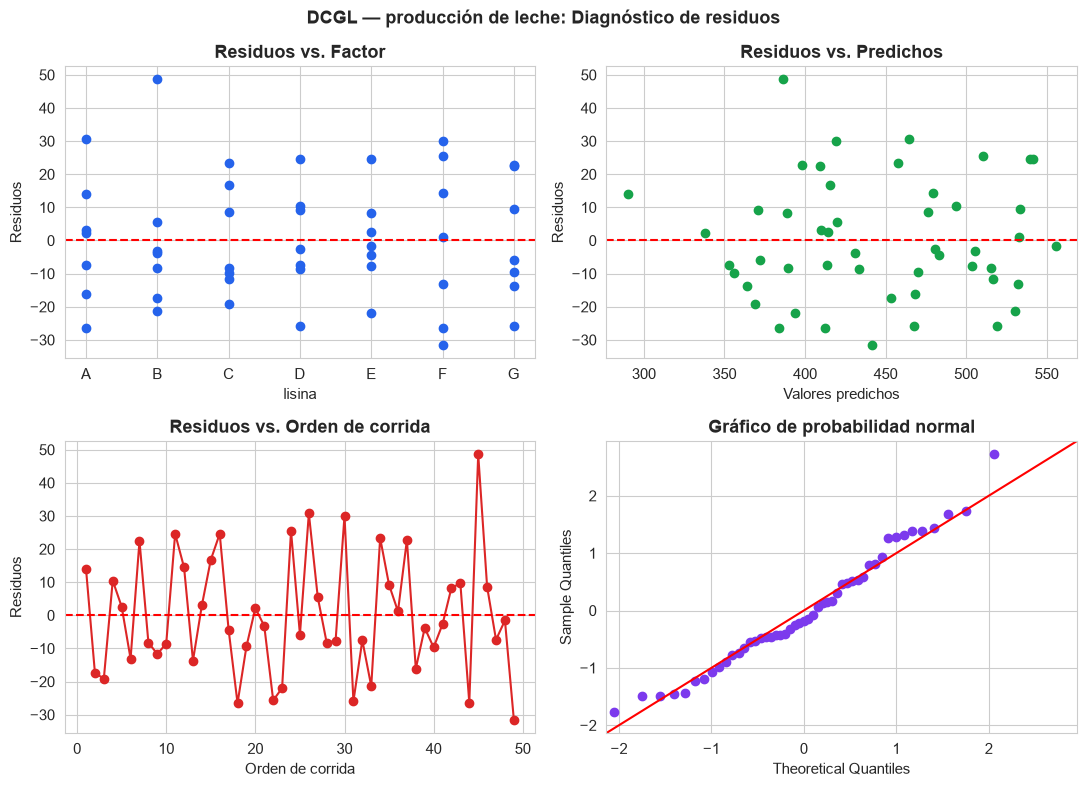

Normalidad   (Shapiro-Wilk sobre residuos): W = 0.9720, valor-p = 0.2915  -> no se rechaza la normalidad
Homocedastic.(Levene por nivel de proteína): W = 0.4576, valor-p = 0.8355  -> varianzas homogéneas
Independencia: garantizada por la aleatorización del cuadro grecolatino.


In [24]:
# =====================================================================
# Verificacion de supuestos del modelo
# =====================================================================
graficar_residuos(modelo_leche, datos_leche, "lisina",
                  titulo_prefijo="DCGL — producción de leche: ")
plt.show()

sw = stats.shapiro(modelo_leche.resid)
lev = stats.levene(*[g["leche"].values for _, g in datos_leche.groupby("proteina")],
                   center="mean")
print(f"Normalidad   (Shapiro-Wilk sobre residuos): W = {sw.statistic:.4f}, "
      f"valor-p = {sw.pvalue:.4f}  -> {'no se rechaza la normalidad' if sw.pvalue > 0.05 else 'se rechaza'}")
print(f"Homocedastic.(Levene por nivel de proteína): W = {lev.statistic:.4f}, "
      f"valor-p = {lev.pvalue:.4f}  -> {'varianzas homogéneas' if lev.pvalue > 0.05 else 'varianzas heterogéneas'}")
print("Independencia: garantizada por la aleatorización del cuadro grecolatino.")


**Conclusión general del ejemplo.**

El porcentaje de **proteína** y el de **lisina** en la dieta afectan significativamente la
producción de leche, pero de forma muy distinta:

- La **proteína** muestra una respuesta **monótona creciente**: pasar de 2 % a 14 % aumenta la
  producción en unos **159 kg** en promedio. Solo el último salto (12 % → 14 %, diferencia de
  10.4 kg) deja de ser significativo, lo que sugiere que el efecto empieza a saturarse.
- La **lisina** concentra casi todo su efecto en **salir del nivel 0 %**: el nivel A (0.0 %) es
  significativamente inferior a los otros seis, mientras que entre B y G las diferencias son
  pequeñas y en su mayoría no significativas. Su mejor nivel es F (0.5 %), no el más alto.

La prueba de **Tukey** (HSD $= 43.68$ kg) declara significativas 15 de las 21 comparaciones de
proteína y 6 de las 21 de lisina; la **LSD de Fisher** (LSD $= 28.08$ kg), al ser menos
conservadora, detecta 17 y 8 respectivamente — las dos adicionales en lisina son E–G y F–G.
La diferencia entre ambas pruebas ilustra el compromiso habitual: Tukey protege el error tipo I
**por familia** de comparaciones, la LSD protege solo cada comparación individual y por eso
encuentra más diferencias.

Los residuos no muestran problemas de normalidad (Shapiro-Wilk, valor-$p = 0.29$) ni de
homogeneidad de varianzas (Levene, valor-$p = 0.84$), de modo que el ANOVA es válido. El cuadro
grecolatino permitió estimar todo esto **con una sola corrida experimental de 49 observaciones**,
controlando simultáneamente la variabilidad entre vacas y entre periodos.

## 7. Diseños de Bloques Incompletos Balanceados (BIBD)

### 7.1 ¿Cuándo se necesita un BIBD?

En el DBCA cada bloque debe contener **todos** los tratamientos. Pero cuando el tamaño del
bloque ($k$) es **menor** que el número de tratamientos ($t$) —por ejemplo, un bloque solo
admite 3 unidades experimentales pero hay 4 tratamientos—, el bloque queda **incompleto**. Un
**Diseño de Bloques Incompletos Balanceados (BIBD)** asigna los tratamientos a los bloques de
manera que **cada par de tratamientos aparece junto, en el mismo bloque, exactamente el mismo
número de veces** ($\lambda$) — de ahí "balanceado".

**Parámetros del diseño:**

* $t$: número de tratamientos.
* $b$: número de bloques.
* $k$: número de tratamientos por bloque ($k<t$).
* $r$: número de repeticiones de cada tratamiento.
* $\lambda$: número de veces que cada **par** de tratamientos coincide en un mismo bloque.

Se cumplen las relaciones:
$$tr = bk \qquad \lambda(t-1) = r(k-1)$$

### 7.2 Modelo estadístico

$$Y_{ij} = \mu + \tau_i + \beta_j + \varepsilon_{ij}$$

igual que en el DBCA, pero ahora $\tau_i$ y $\beta_j$ están **confundidos** (no se puede
separar limpiamente el efecto de un tratamiento del efecto del bloque en el que apareció),
por lo que se necesita un **análisis intrabloque ajustado**.

### 7.3 Análisis intrabloque (fórmulas de Yates)

Para cada tratamiento $i$, se define el **total ajustado**:

$$Q_i = T_i - \frac{1}{k}\sum_{j \,:\, i \in \text{bloque } j} B_j$$

donde $T_i$ es el total (sin ajustar) del tratamiento $i$ y $B_j$ es el total del bloque $j$.
Se cumple $\sum_i Q_i = 0$.

$$SC_{Tratamiento}(\text{ajustada}) = \frac{k\sum_i Q_i^2}{\lambda\, t}$$

$$SC_{Bloque}(\text{sin ajustar}) = \sum_j \frac{B_j^2}{k} - \frac{Y_{\cdot\cdot}^2}{N}, \qquad N = tr = bk$$

$$SCE = SCT - SC_{Tratamiento}(\text{ajustada}) - SC_{Bloque}(\text{sin ajustar})$$

**Tabla ANOVA**

| Fuente | SC | gl |
|---|---|---|
| Tratamientos (ajustados) | $SC_{Tr}$ | $t-1$ |
| Bloques (sin ajustar) | $SC_{B}$ | $b-1$ |
| Error | $SCE$ | $N-t-b+1$ |
| Total | $SCT$ | $N-1$ |

El efecto ajustado de cada tratamiento se estima como $\hat{\tau}_i = \dfrac{k\,Q_i}{\lambda\,t}$,
y la media ajustada es $\hat{\mu}_i = \bar{Y}_{\cdot\cdot} + \hat{\tau}_i$.


### 7.4 Ejercicio resuelto (ilustrativo)

Se comparan **4 catalizadores (A, B, C, D)** para un proceso químico, midiendo el
**rendimiento de reacción**. Cada corrida del reactor solo admite **3** catalizadores a la vez
($k=3<t=4$), por lo que se usa el BIBD "no reducido" con $b=t=4$ bloques (cada bloque omite
exactamente un catalizador), $r=3$, $\lambda = r(k-1)/(t-1) = 3\cdot2/3 = 2$.

*(Datos ilustrativos construidos para fines pedagógicos.)*

| Bloque | Catalizadores | Rendimientos |
|---|---|---|
| 1 | A, B, C | 8, 11, 10 |
| 2 | A, B, D | 8, 11, 15 |
| 3 | A, C, D | 8, 10, 11 |
| 4 | B, C, D | 12, 14, 14 |


In [25]:
# =====================================================================
# BIBD: t=4 catalizadores, b=4 bloques, k=3, r=3, lambda=2
# =====================================================================
datos_bibd = pd.DataFrame({
    "bloque":     [1, 1, 1,  2, 2, 2,  3, 3, 3,  4, 4, 4],
    "tratamiento": ["A", "B", "C",  "A", "B", "D",  "A", "C", "D",  "B", "C", "D"],
    "rendimiento": [8, 11, 10,   8, 11, 15,   8, 10, 11,   12, 14, 14],
})

t_b, b_b, k_b = 4, 4, 3
N_b = len(datos_bibd)
r_b = N_b * k_b // (t_b * k_b)          # repeticiones por tratamiento (r = N/t)
r_b = datos_bibd["tratamiento"].value_counts().iloc[0]
lam_b = r_b * (k_b - 1) // (t_b - 1)
print(f"t={t_b}, b={b_b}, k={k_b}, r={r_b}, lambda={lam_b}  (verifica: t*r == b*k -> {t_b*r_b} == {b_b*k_b})")

T_i = datos_bibd.groupby("tratamiento")["rendimiento"].sum()
B_j = datos_bibd.groupby("bloque")["rendimiento"].sum()
G = datos_bibd["rendimiento"].sum()

print("\nTotales por tratamiento T_i:\n", T_i)
print("\nTotales por bloque B_j:\n", B_j)
print(f"\nTotal general G = {G},  N = {N_b},  media general = {G / N_b:.4f}")


t=4, b=4, k=3, r=3, lambda=2  (verifica: t*r == b*k -> 12 == 12)

Totales por tratamiento T_i:
 tratamiento
A    24
B    34
C    34
D    40
Name: rendimiento, dtype: int64

Totales por bloque B_j:
 bloque
1    29
2    34
3    29
4    40
Name: rendimiento, dtype: int64

Total general G = 132,  N = 12,  media general = 11.0000


In [26]:
# =====================================================================
# Totales ajustados Q_i y suma de cuadrados de tratamiento ajustada
# =====================================================================
bloques_por_trat = datos_bibd.groupby("tratamiento")["bloque"].apply(set)

Q_i = {}
for trat in T_i.index:
    suma_bloques = sum(B_j[j] for j in bloques_por_trat[trat])
    Q_i[trat] = T_i[trat] - suma_bloques / k_b

Q_i = pd.Series(Q_i)
print("Totales ajustados Q_i:\n", Q_i.round(4))
print(f"\nSuma de Q_i (debe ser ~0): {Q_i.sum():.6f}")

SC_trat_adj = k_b * (Q_i ** 2).sum() / (lam_b * t_b)
SC_bloque_sinaj = (B_j ** 2).sum() / k_b - G ** 2 / N_b
SC_total = (datos_bibd["rendimiento"] ** 2).sum() - G ** 2 / N_b
SC_error = SC_total - SC_trat_adj - SC_bloque_sinaj

gl_trat = t_b - 1
gl_bloque = b_b - 1
gl_error = N_b - t_b - b_b + 1
gl_total = N_b - 1

CM_trat = SC_trat_adj / gl_trat
CM_error = SC_error / gl_error
F0 = CM_trat / CM_error
p_valor = 1 - stats.f.cdf(F0, gl_trat, gl_error)

tabla_bibd = pd.DataFrame({
    "SC": [SC_trat_adj, SC_bloque_sinaj, SC_error, SC_total],
    "gl": [gl_trat, gl_bloque, gl_error, gl_total],
}, index=["Tratamiento (ajustado)", "Bloque (sin ajustar)", "Error", "Total"])
tabla_bibd["CM"] = tabla_bibd["SC"] / tabla_bibd["gl"]
tabla_bibd.loc["Tratamiento (ajustado)", "F0"] = F0
tabla_bibd.loc["Tratamiento (ajustado)", "valor-p"] = p_valor
tabla_bibd.round(4)


Totales ajustados Q_i:
 A   -6.6667
B   -0.3333
C    1.3333
D    5.6667
dtype: float64

Suma de Q_i (debe ser ~0): -0.000000


,SC,gl,CM,F0,valor-p
Tratamiento (ajustado),29.4167,3,9.8056,6.7625,0.0328
Bloque (sin ajustar),27.3333,3,9.1111,NaN,NaN
Error,7.2500,5,1.4500,NaN,NaN
Total,64.0000,11,5.8182,NaN,NaN


In [27]:
# =====================================================================
# Efectos y medias ajustadas por catalizador
# =====================================================================
tau_hat = k_b * Q_i / (lam_b * t_b)
media_general = G / N_b
medias_ajustadas = media_general + tau_hat

resumen_bibd = pd.DataFrame({
    "Q_i": Q_i,
    "tau_i (ajustado)": tau_hat,
    "Media ajustada": medias_ajustadas,
    "Media cruda": T_i / r_b,
}).round(4)
resumen_bibd


,Q_i,tau_i (ajustado),Media ajustada,Media cruda
A,-6.6667,-2.500,8.500,8.0000
B,-0.3333,-0.125,10.875,11.3333
C,1.3333,0.500,11.500,11.3333
D,5.6667,2.125,13.125,13.3333


**Conclusión:** con $F_0 > F_{\alpha}(t-1, N-t-b+1)$ (comparar con la tabla $F$ o el
valor-$p$ calculado), se concluye si existen diferencias significativas entre catalizadores.
A diferencia del DBCA, aquí las medias **ajustadas** son las que se deben comparar (no las
medias crudas), porque cada tratamiento aparece en un subconjunto distinto de bloques y las
medias crudas están parcialmente confundidas con el efecto de bloque.


## 8. Resumen del capítulo 4 — Diseños en bloques

| Diseño | Fuentes de variación controladas | Requisito clave | Cuándo usarlo |
|---|---|---|---|
| **DBCA** | 1 (el bloque) | cada bloque contiene todos los tratamientos | hay una única fuente de variabilidad extraña conocida (p. ej. operador, lote) |
| **Bloque aleatorio** | 1 (el bloque, tratado como muestra aleatoria) | igual que DBCA | los bloques son una muestra de una población más amplia y se quiere generalizar |
| **DCL** | 2 (fila y columna) | $t$ tratamientos = $t$ filas = $t$ columnas | dos fuentes de variabilidad extrañas, cada una con el mismo número de niveles que los tratamientos |
| **DCGL** | 3 (fila, columna, 2.º tratamiento) | dos cuadrados latinos ortogonales | se quiere estudiar dos factores de tratamiento controlando dos fuentes de variabilidad extrañas, en pocas corridas |
| **BIBD** | 1 (el bloque), pero de tamaño limitado | $k<t$; cada par de tratamientos coincide $\lambda$ veces | el tamaño del bloque no permite incluir todos los tratamientos |

**Puntos clave para recordar:**

1. El **bloqueo** no elimina la variabilidad — la **remueve del término de error**,
   aumentando la potencia para detectar diferencias entre tratamientos.
2. Cuantas más fuentes de variación se controlen (DCL, DCGL), **menos grados de libertad**
   quedan para el error — hay un balance entre control de variabilidad y precisión de la
   estimación del error.
3. En el BIBD, siempre se deben comparar **medias ajustadas**, nunca las medias crudas.
4. Las pruebas de comparación múltiple (**Tukey**, **LSD de Fisher**) se aplican después de
   un ANOVA significativo, usando el $CME$ y los grados de libertad del error de la tabla
   ANOVA correspondiente a cada diseño.
